In [36]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(".."))
from churn.datos import cargar_datos, limpiar_nombres_columnas, reporte_calidad, tasa_por_grupo
from churn.modelo import dividir_datos, limpiar_negativos, construir_modelo, construir_preprocesador
from churn.eda import graficar_tasa
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline, make_pipeline
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import TargetEncoder

In [2]:
df = cargar_datos("../data/dataset.csv")

In [3]:
X_train, X_test, y_train, y_test = dividir_datos(df)

In [4]:
print(y_train.mean())
print(y_test.mean())

0.495625
0.4956


In [5]:
num_cols = [
    "rev_Mean",         # Mean monthly revenue (charge amount)
    "mou_Mean",         # Mean number of monthly minutes of use
    "ovrrev_Mean",      # Mean overage revenue
    "comp_dat_Mean",    # Mean number of completed data calls
    "custcare_Mean",    # Mean number of customer care calls
    "phones",           # Number of handsets issued
    "months",           # Total number of months in service
    "eqpdays",          # Number of days (age) of current mobile phone
    "change_mou",       # Percentage change in monthly minutes of use vs previous three month average
    "change_rev",       # Percentage change in monthly revenue vs previous three month average
    "drop_vce_Mean",    # Mean number of dropped (failed) voice calls
    "drop_dat_Mean",    # Mean number of dropped (failed) data calls
    "drop_blk_Mean",    # Mean number of dropped or blocked calls
    "blck_vce_Mean",    # Mean number of blocked (failed) voice calls
    "blck_dat_Mean",    # Mean number of blocked (failed) data calls
    "unan_dat_Mean",    # Mean number of unanswered data calls
    "totmrc_Mean",      # Mean total monthly recurring charge
    "uniqsubs",         # Number of unique subscribers in the household
    # "actvsubs",         # Number of active subscribers in household. Se descarta por multicolinealidad con uniqsubs
    "roam_Mean",        # Mean number of roaming calls
    "datovr_Mean",      # Mean revenue of data overage
    "da_Mean",          # Mean number of directory assisted calls
    "recv_sms_Mean",    # Mean number of received sms
    "callfwdv_Mean",    # Mean number of call forwarding calls
    "callwait_Mean",    # Mean number of call waiting calls
    "threeway_Mean",    # Mean number of three way calls
    "hnd_price",        # Current handset price
    # "adults",           # Number of adults in household
    # "income",           # Estimated income
    # "numbcars",         # Known number of vehicles
    # "forgntvl",         # Foreign travel dummy variable
    # "truck",            # Truck indicator
    # "rv",               # RV indicator
    # "lor"               # Length of residence
]

In [6]:
df.select_dtypes(include="str").columns

Index(['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area',
       'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype',
       'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2',
       'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd'],
      dtype='str')

In [7]:
diccionario_datos = pd.read_csv("../data/data_descriptions.csv", sep=";")
diccionario_datos['Variable'] = limpiar_nombres_columnas(diccionario_datos['Variable'])
desc_por_clave = dict(zip(diccionario_datos['Variable'], diccionario_datos['Significado']))

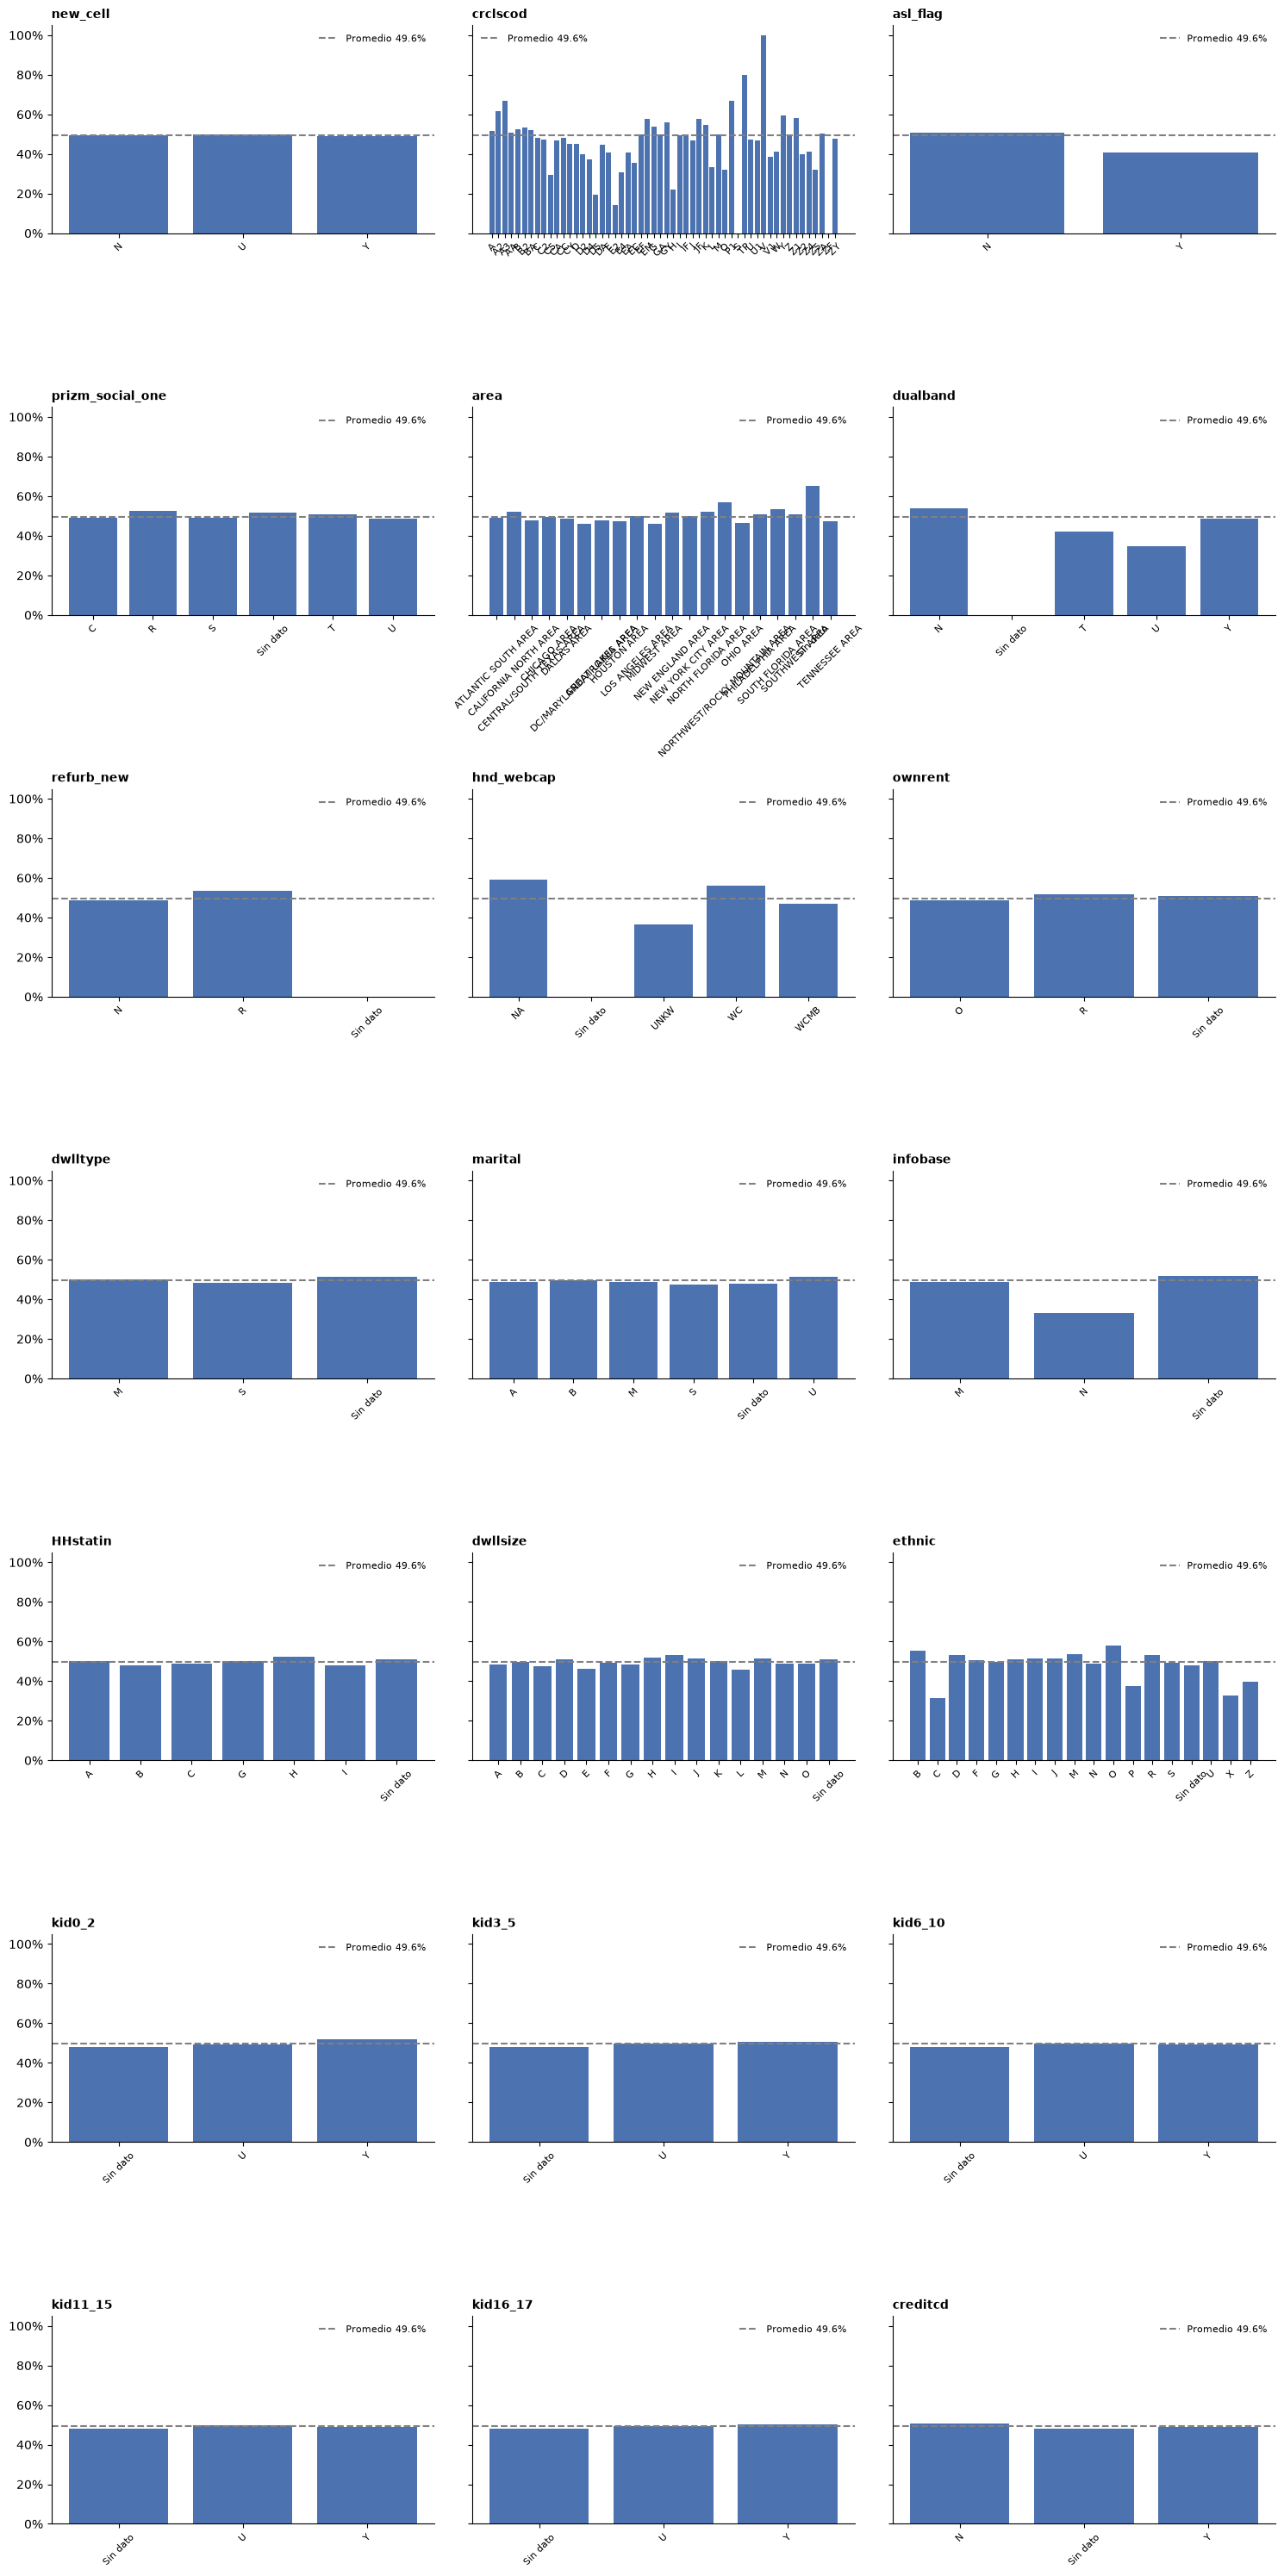

In [8]:
promedio_global = df['churn'].mean()

str_columns = df.select_dtypes(include="str").columns
fig, axes = plt.subplots(round(len(str_columns)/3), 3, figsize=(15,30), sharey=True)
for var, ax in zip( str_columns, axes.flatten()):
    df_val = df.copy()
    df_val[var] = df_val[var].fillna("Sin dato")

    tabla = df_val.groupby(var)['churn'].mean().to_frame(name='tasa_churn')
    graficar_tasa(tabla, f"{var}", promedio_global, ax=ax)

plt.tight_layout()
plt.show()

In [9]:
# Estas columnas fueron seleccionadas porque fueron en las que encontré mayor variabilidad entre grupos.
# Las columnas que dejé fuera fue o poruqe no mostraban gran variabilidad o por cuestiones éticas (variables sensibles).
cat_cols = [
    "refurb_new", # Handset: refurbished or new
    "infobase", # InfoBase match
    "dualband", # Dualband
    "asl_flag", # Account spending limit
    "hnd_webcap", # Handset web capability
    # "crclscod"
]

In [10]:
# for var in cat_cols:
#     desc = desc_por_clave.get(var.lower())
#     if not desc: raise ValueError(f"Variable '{var}' no encontrada")
#     print(f'"{var}", # {desc}')

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultado_regresion = cross_validate(
    construir_modelo(num_cols, cat_cols),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [15]:
dummy_clf = DummyClassifier()
dummy_clf.fit(X_train,y_train)

resultado_dummy = cross_validate(
    dummy_clf,
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [16]:

puntuacion_regla = X_train["eqpdays"].fillna(X_train["eqpdays"].median())
resultado_eqpdays = roc_auc_score(y_train, puntuacion_regla)

In [17]:
def resumir_cv(nombre: str, resultado: dict) -> dict:
    return {
        "modelo": nombre,
        "auc_train": resultado["train_score"].mean(),
        "auc_val": resultado["test_score"].mean(),
        "auc_val_std": resultado["test_score"].std(),
    }

filas = [
    resumir_cv("Regresión logística", resultado_regresion),
    resumir_cv("DummyClassifier", resultado_dummy),
    {
        "modelo": "Regla 'eqpdays'",
        "auc_train": np.nan,
        "auc_val": resultado_eqpdays,
        "auc_val_std": np.nan,
    }
]
pd.DataFrame(filas)

,modelo,auc_train,auc_val,auc_val_std
0,Regresión logística,0.611872,0.610183,0.003481
1,DummyClassifier,0.500000,0.500000,0.000000
2,Regla 'eqpdays',NaN,0.574664,NaN


En Regresión logística se observa un desempeño bajo en train y en val, ambos parecidos. Esto quiere decir que hay un underfitting

In [18]:
c_tests = [0.01,0.1, 1, 10]

filas = []
for c in c_tests:
    resultado_c = cross_validate(
        construir_modelo(num_cols, cat_cols, c),
        X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        error_score="raise"
    )
    filas.append(resumir_cv(f"Regresión logística (c={c})", resultado_c))
pd.DataFrame(filas)

,modelo,auc_train,auc_val,auc_val_std
0,Regresión logística (c=0.01),0.611796,0.610134,0.003412
1,Regresión logística (c=0.1),0.611889,0.610181,0.003483
2,Regresión logística (c=1),0.611872,0.610183,0.003481
3,Regresión logística (c=10),0.611876,0.610176,0.003462


Con diferentes valores de C los resultados se mantienen practicamente iguales. Esto puede indicar que un modelo lineal no está ayudando a representar bien los datos. Mis datos no son lineales.

La variable months tampoco es lineal, empieza abajo, luego sube y luego sigue bajando, al no tener un comportamiento lineal, el modelo de Regresión Logística no interpreta bien estos datos.

La regularización sirve para frenar el sobreajuste. Si el modelo no sobreajusta (con 80,000 clientes y ~50 variables, tiene datos de sobra), quitar o poner freno da igual. El límite no está en cuánto se ajusta el modelo, sino en la forma que puede representar. Las salidas son variables nuevas que capturen esas formas (por ejemplo, convertir months en segmentos) o un modelo no lineal: árboles

In [19]:
pipeline : Pipeline = construir_modelo(num_cols, cat_cols)
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpieza', ...), ('pre', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](98,)","['rev_Mean','mou_Mean','totmrc_Mean',...,'kid16_17','creditcd','eqpdays']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,98
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...x7c468ef680e0>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None


In [20]:
nombres = pipeline[:-1].get_feature_names_out()
coeficientes = pipeline[-1].coef_[0]

importancia_coefs = pd.Series(coeficientes, index=nombres)

print("--- Top 10 Coeficientes Positivos (Aumentan riesgo de churn) ---")
display(importancia_coefs.nlargest(10))

print("\n--- Top 10 Coeficientes Negativos (Reducen riesgo de churn) ---")
display(importancia_coefs.nsmallest(10))


--- Top 10 Coeficientes Positivos (Aumentan riesgo de churn) ---


num__eqpdays              0.280661
cat__infobase_Sin dato    0.272084
num__change_rev           0.136148
cat__asl_flag_N           0.123440
num__ovrrev_Mean          0.102571
num__phones               0.102481
cat__hnd_webcap_UNKW      0.095760
cat__refurb_new_R         0.077186
num__uniqsubs             0.074928
num__rev_Mean             0.071112
dtype: float64


--- Top 10 Coeficientes Negativos (Reducen riesgo de churn) ---


cat__infobase_N                  -0.373716
num__months                      -0.194293
cat__asl_flag_Y                  -0.165446
num__change_mou                  -0.150033
num__mou_Mean                    -0.145583
cat__refurb_new_N                -0.119120
cat__dualband_T                  -0.113017
num__missingindicator_rev_Mean   -0.092322
cat__hnd_webcap_WCMB             -0.081460
num__totmrc_Mean                 -0.073842
dtype: float64

Los resultados numericos coinciden con mi EDA. Sin embargo me llaman la atención los coeficientes de la variable categorica infobase, es la que más domina en los coeficientes negativos y la segunda en los positivos. Esta variable es el InfoBase match, lo que no se refiere a un comportamiento real del cliente y parece estar sesgando el modelo.

| Coeficiente                                       |	¿Coincide con el EDA?                   |
|---------------------------------------------------|-------------------------------------------|
|eqpdays + (el más alto)                            |	Si. Teléfono más viejo, más riesgo      |
|change_mou −                                       |	Si. Si el uso cae, sube el riesgo       |
|mou_Mean −, refurb_new_N −, hnd_webcap_WCMB −	    |   Si.                                     |
|months −	                                        |Solo una parte. El modelo ve "más antigüedad, menos riesgo", pero no el pico del año, porque no puede representarlo. Esta es la evidencia concreta de tu punto 2  |
|missingindicator_change_mou +	                    |Si. El grupo de 891 clientes sin dato que encontraste en la Lección 5. add_indicator está funcionando                                                       |
|hnd_webcap_UNKW +	                                |No. Contradice el EDA (36.6 %, tasa baja). Son solo 235 cliente|

A. uniqsubs + 0.17 y actvsubs − 0.12: signos opuestos. Su correlación de Spearman es 0.83. Es la multicolinealidad: dos variables que dicen casi lo mismo, y el modelo "compensa" una con la otra. En el EDA, uniqsubs aumenta el riesgo de forma consistente (47.7 % con 1 suscriptor, 54.9 % con 4). Leído por separado, el coeficiente de actvsubs sugeriría lo contrario, y sería una conclusión falsa.

In [21]:
tasa_por_grupo(df, "infobase", True)

,n_clientes,tasa_churn
infobase,,
NaN,22079,0.519815
M,77697,0.489221
N,224,0.330357


Hay dos problemas:

1. El coeficiente más grande del modelo (−0.30) viene de un grupo de 224 clientes. Los grupos chicos producen estimaciones extremas e inestables. Además, los coeficientes de una columna 0/1 no se comparan directamente con los de una numérica estandarizada: están en escalas distintas.

In [ ]:
combinacion = (
    X_train["area"].fillna("?")
    + "_" + X_train["crclscod"].fillna("?")
    + "_" + X_train["months"].astype(str)
)
combinacion.nunique()

8348

In [30]:
combinacion.value_counts().describe()

count    8348.000000
mean        9.583134
std        18.982628
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       271.000000
Name: count, dtype: float64

In [31]:
tasa_con_fuga = y_train.groupby(combinacion).transform("mean")

In [34]:
resultado_fuga = cross_validate(
    LogisticRegression(),
    tasa_con_fuga.to_frame(),      # .to_frame(): sklearn espera una tabla, no una Series
    y_train,
    cv=cv, scoring="roc_auc",
)
resultado_fuga["test_score"].mean()     # ~0.71

np.float64(0.7074227604926001)

In [37]:
modelo_correcto = make_pipeline(TargetEncoder(), LogisticRegression())

resultado_correcto = cross_validate(
    modelo_correcto,
    combinacion.to_frame(),        # ahora entra la categórica original, sin codificar
    y_train,
    cv=cv, scoring="roc_auc",
)
resultado_correcto["test_score"].mean()     # ~0.58

np.float64(0.5751096287059478)

In [58]:
pd.DataFrame([
    {
        "Modelo": "Logística completa (E4)",
        "Variables": len(num_cols) + len(cat_cols),
        "AUC de validación": resultado_regresion["test_score"].mean()
    },
    {
        "Modelo": "Target encoding con fuga",
        "Variables": 1,
        "AUC de validación": resultado_fuga["test_score"].mean()
    },
    {
        "Modelo": "Target encoding correcto",
        "Variables": 1,
        "AUC de validación": resultado_correcto["test_score"].mean()
    }
])

,Modelo,Variables,AUC de validación
0,Logística completa (E4),31,0.610183
1,Target encoding con fuga,1,0.707423
2,Target encoding correcto,1,0.575110
